
**Завдання 1**: Завантажте дані `medical-charges.csv` в пандас датафрейм і виведіть перші 5 записів. Напишіть, як ви можете підійти до вирішення задачі прогнозування колонки `charges` на основі інших колонок виходячи з наявних на даний момент знань (без ML методів, чисто з використанням аналітики). Запишіть 3 або більше ідей, які приходять вам на думку нижче:

In [146]:
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import numpy as np

In [147]:
mc_df = pd.read_csv("medical-charges.csv")
mc_df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [148]:
# My ideas for analysis:
# 1. I will analize relationship between age and charges. Older - more charges?
# 2. Analize relationship between bmi and charges. Higher BMI - more charges?
# 3. Analize relationship between smoker and charges. Smokers - more charges?

**Завдання 2**: Візуалізуйте розподіл медичних зборів (`charges`) у вигляді інтерактивної гістограми plotly з розбиттями за категоріями ознак
1. `sex`
2. `region`

Додайте маржинальний графік у вигляді бокс-плота вгорі по дикретним категоріям ознак.
Скористайтесь прикладом візуалізації з лекції.
Опишіть свої спостереження.

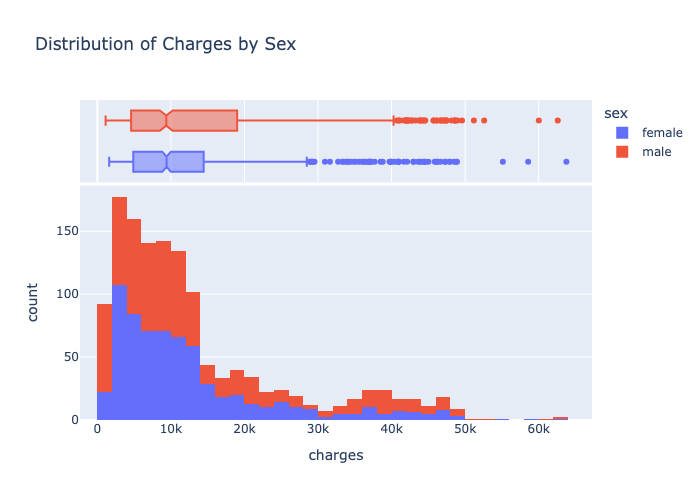

In [149]:
fig = px.histogram(mc_df,
                   x='charges',
                   marginal='box',
                   color='sex',
                   color_discrete_sequence=['#636EFA', '#EF553B'],
                   title='Distribution of Charges by Sex')
fig.update_layout()
fig.show(renderer='plotly_mimetype+png')

In [150]:
 # I see that the distribution of charges is right skewed
 # most people having lower charges and a few having very high charges
 # there are some outliers
 # male and female have approximately the same median
 # there is a gap between F and M in Q3 - approximatelly 4.5. In this case M charges are bigger.

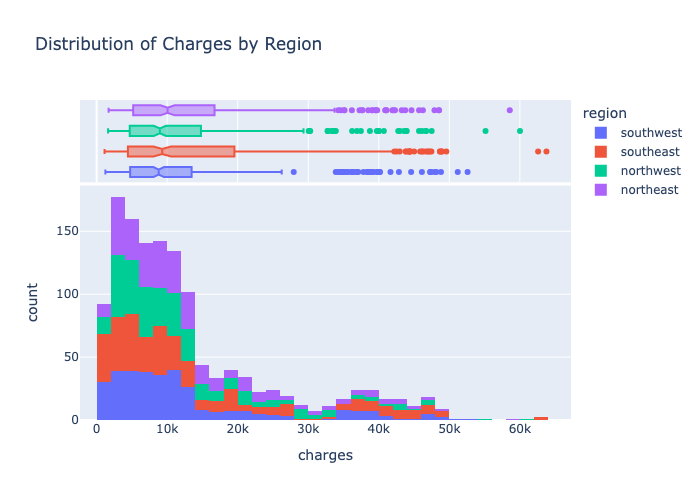

In [151]:
fig = px.histogram(mc_df,
                   x='charges',
                   marginal='box',
                   color='region',
                   color_discrete_sequence=['#636EFA', '#EF553B', '#00CC96', '#AB63FA'],
                   title='Distribution of Charges by Region')
fig.update_layout()
fig.show(renderer='plotly_mimetype+png')

In [152]:
# I see that the distribution of charges is right skewed
# there are some outliers
# the distribution of charges is approximately the same for all regions
# median in each region has small gap
# Q3 is bigger in southeast with the gap with southwest in approximately 6

**Завдання 3**: Візуалізуйте з `plotly` розподіл кожного з настуних стовпців відносно того, чи є людина курцем (`smoker`)
- `region`
- `children`

та опишіть коротко свої спостереження.

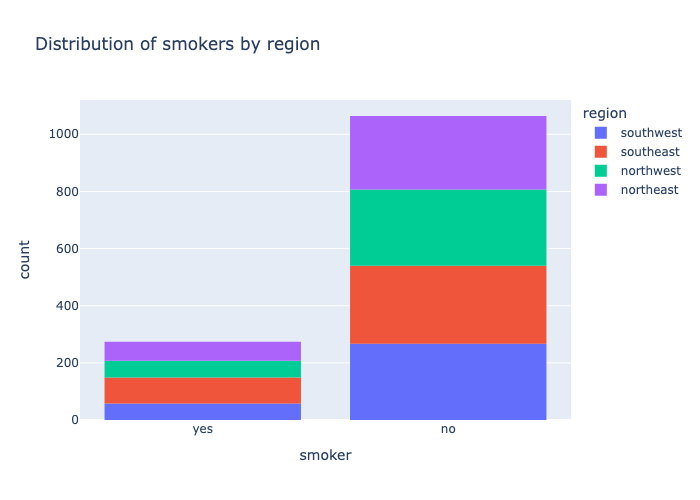

In [153]:
fig = px.histogram(mc_df,
                   x='smoker',
                   color='region',
                   color_discrete_sequence=['#636EFA', '#EF553B', '#00CC96', '#AB63FA'],
                   title='Distribution of smokers by region')
fig.update_layout()
fig.show(renderer='plotly_mimetype+png')

In [154]:
# the biggest group of smokers are from southeast - 91

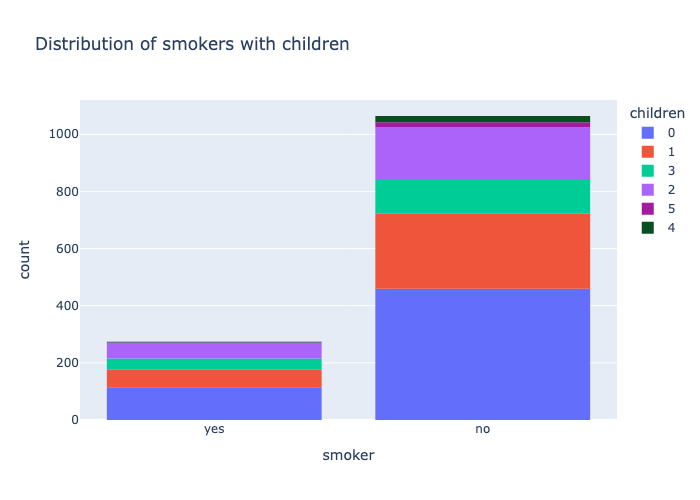

In [155]:
fig = px.histogram(mc_df,
                   x='smoker',
                   color='children',
                   color_discrete_sequence=['#636EFA', '#EF553B', '#00CC96', '#AB63FA', "#A31BA1", "#0A4F1F"],
                   title='Distribution of smokers with children')
fig.update_layout()
fig.show(renderer='plotly_mimetype+png')

In [156]:
# the most people with 4 and more children are non-smokers (only 3 with 4 children are smokers)
# the most smokers and non-smokers have 0 children
# in non-smokers - the group is getting smaller when the number of children are getting bigger

**Завдання 4**: Візуалізуйте звʼязок між стовпцем `charges` та `children` використовуючи графіки-скрипки (`px.violin`). Опишіть свої спостереження.

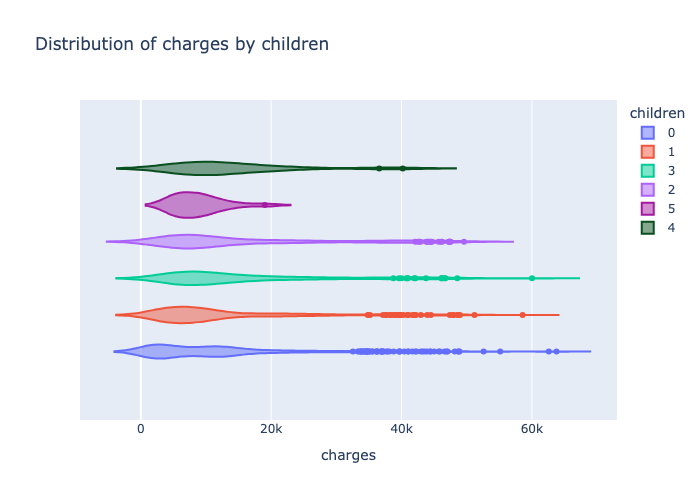

In [157]:
fig = px.violin(mc_df,
                   x='charges',
                   color='children',
                   color_discrete_sequence=['#636EFA', '#EF553B', '#00CC96', '#AB63FA', "#A31BA1", "#0A4F1F"],
                   title='Distribution of charges by children')
fig.update_layout()
fig.show(renderer='plotly_mimetype+png')

In [158]:
# 0 children - median is 9.85, Q3 is 14.44
# 1 child - mdeian is 8.48, Q3 is 15.9
# 2 children - median is 9.26, Q3 is 20.58
# 3 children - median is 10.60, Q3 is 19.24
# 4 children - median is 11.03, Q3 is 17.33
# 5 children - median is 8.58, Q3 is 10.09

**Завдання 5.** Розглянемо модель для користувачів, які не є курцями (`no_smoker_df`):

$$charges = w \times age + b$$

Спробуйте 3 різні пари параметрів `w` та `b` аби вручну підігнати лінію під дані використовуючи наведені допоміжні функції `estimate_charges` та `try_parameters`. Опишіть спостереження.
Пари параметрів мають бути НЕ такі, як були наведені в лекції.

In [159]:
non_smoker_df = mc_df[mc_df.smoker == 'no']

In [160]:
def estimate_charges(age, w, b):
    return w * age + b

In [161]:
def try_parameters(df, w, b):
    ages = df.age
    target = df.charges

    estimated_charges = estimate_charges(ages, w, b)

    plt.plot(ages, estimated_charges, 'r', alpha=0.9);
    plt.scatter(ages, target, s=8,alpha=0.8);
    plt.xlabel('Age');
    plt.ylabel('Charges')
    plt.legend(['Estimate', 'Actual']);

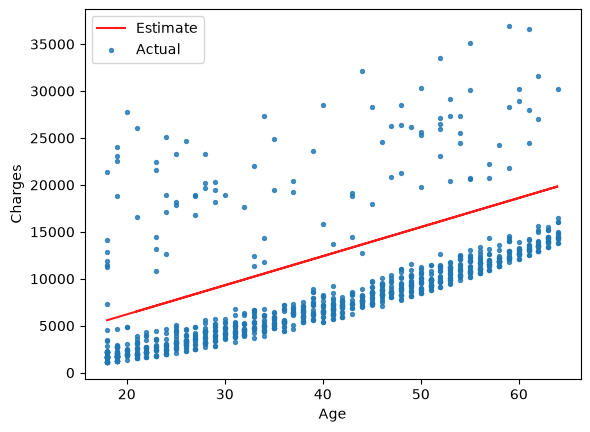

In [162]:
try_parameters(non_smoker_df, 310, 10)

In [163]:
# I try random values
# w = 310 - every additional year adds 310 to predicted charge
# b = 10 - shifts the line up or down. 
# the model multiplies age by 310 and add 10, ex: 20*310+10
# prediction at age 50
50*310+10

15510

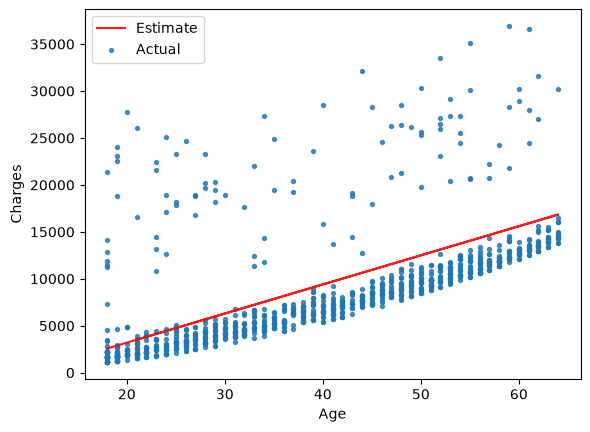

In [164]:
try_parameters(non_smoker_df, 310, -3000)

In [165]:
# I try lower b
# w = 310
# b = -3000
# the model multiplies age by 310 and substract 3000, ex: 20*310-3000
# prediction at age 50
50*310-3000

12500

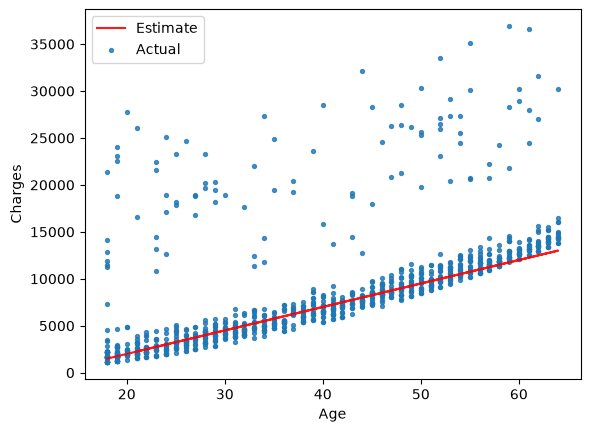

In [166]:
try_parameters(non_smoker_df, 250, -3000)

In [167]:
# I try lower w
# w = 250
# b = -3000
# the model multiplies age by 250 and substract 3000, ex: 20*250-3000
# prediction at age 50
50*250-3000

9500

In [168]:
# lower b - shifts the line down
# lower w - made the line flatter

**Завдання 6**: Напишіть фукнцію для обчислення root mean squared error згідно з формулою цієї метрики точності моделі з використанням `numpy`.

Обчисліть RMSE для тих пар пареметрів, які Ви спробували в завданні 5.

Яке найнижче значення втрат ви зможете досягти? Чи можете ви придумати загальну стратегію для знаходження кращих значень $w$ та $b$ методом проб та помилок?

In [169]:
def rmse(targets, predictions):
    return np.sqrt(np.mean(np.square(targets - predictions)))

In [170]:
non_smoker_df.charges.describe()

count     1064.000000
mean      8434.268298
std       5993.781819
min       1121.873900
25%       3986.438700
50%       7345.405300
75%      11362.887050
max      36910.608030
Name: charges, dtype: float64

In [171]:
targets = non_smoker_df['charges']
predicted = estimate_charges(non_smoker_df.age, 310, 10)
rmse(targets, predicted)

np.float64(6035.624116959586)

In [172]:
targets = non_smoker_df['charges']
predicted = estimate_charges(non_smoker_df.age, 310, -3000)
rmse(targets, predicted)

np.float64(4764.665278198029)

In [173]:
targets = non_smoker_df['charges']
predicted = estimate_charges(non_smoker_df.age, 250, -3000)
rmse(targets, predicted)

np.float64(4931.47542485992)

In [174]:
# 310, -3000 gave the lowest RMSE = 4,764.67